<table style="border:0;width:100%;border-collapse:collapse"><tr style="border:0"><td style="border:0;width:105px;vertical-align:middle"><img src="../Imagenes/logo-final-ap.png" width="90"/></td><td style="border:0;vertical-align:middle"><span style="font-size:32px;font-weight:700;color:#bd232b">Aprendizaje Profundo</span></td></tr></table>

[https://github.com/AprendizajeProfundo](https://github.com/AprendizajeProfundo)

# <span style="color:#174ea6">Cuaderno 103 · Gradientes de política y métodos Actor-Crítico</span>

**Sesión 2 · De aprender valores a aprender políticas; preparación para PPO y Hydro-Lab**

**Autores:** Alvaro Montenegro · Daniel Montenegro · Pilar Montenegro  
**Docente:** Alvaro Montenegro, [ammontenegrod@gmail.com](mailto:ammontenegrod@gmail.com),  
**Institución:** Universidad de los Andes - Ecopetrol  
**Edición docente:** 103 · Octubre de 2026  
**Licencia del contenido y código originales de esta edición:** MIT (véase sección final).

> **Pregunta rectora.** ¿Cómo optimizar directamente una política estocástica y por qué estimar una función de valor puede reducir la variabilidad de su aprendizaje?

**Fuentes directas:** `12_ar_Gradientes_Politica.ipynb`, `13_ar_Actor_Critico.ipynb`; antecedentes conceptuales `07_ar_Metodo_Entropia_Cruzada_Introducción.ipynb` y `08_ar_Metodo_Entropia_Cruzada_implementacion.ipynb`. Los originales no se modifican.

## <span style="color:#bd232b">Guía de navegación y resultados de aprendizaje</span>

**Tiempo orientativo de clase: 45 minutos.** El entrenamiento completo y las ampliaciones se pueden ejecutar fuera de clase.

| Tramo | Minutos | Evidencia |
|---|---:|---|
| Del valor a la política; teorema del gradiente | 0–12 | Derivación y comprensión del estimador |
| REINFORCE en CartPole | 12–25 | Curva de retorno y evaluación |
| Baselines, ventaja y Actor-Crítico | 25–38 | Estimación TD y actualización conjunta |
| Hydro-Lab y transición a PPO | 38–45 | Diseño de política para acciones continuas |

**Al terminar podrás:** derivar el estimador REINFORCE, distinguir retorno/valor/ventaja, implementar un actor-crítico simple, separar entrenamiento de evaluación y reconocer qué elementos aprovecha PPO.

**Dependencias:** `numpy`, `matplotlib`, `torch`; `gymnasium` para CartPole. El cuaderno incluye una prueba de gradientes independiente de Gymnasium. El entrenamiento usa CPU por defecto para ser reproducible en equipos distintos.

## <span style="color:#bd232b">1. De Q-learning a la optimización directa de políticas</span>

En el cuaderno 102 aproximamos $Q(s,a)$ y seleccionamos una acción mediante $\arg\max_a Q(s,a)$. En métodos basados en políticas representamos directamente

$$
\pi_\theta(a\mid s)=\Pr(A_t=a\mid S_t=s;\theta),
$$

y buscamos parámetros $\theta$ que maximicen el retorno esperado. La política puede ser estocástica, lo que permite explorar y, más adelante, manejar acciones continuas.

En un MDP episódico, definimos la trayectoria $\tau=(s_0,a_0,r_1,\ldots,s_T)$ y el retorno descontado desde $t$:

$$G_t=\sum_{k=0}^{T-t-1}\gamma^k r_{t+k+1}.$$

Para evitar ambigüedad en la derivación, primero consideramos el objetivo de **retorno total no descontado** $J(\theta)=\mathbb E_{\tau\sim p_\theta}[\sum_{t=0}^{T-1}r_{t+1}]$ en un horizonte finito. La versión descontada requiere precisar la ponderación temporal del objetivo; en la implementación utilizaremos retornos descontados $G_t$ como señal de entrenamiento.

**Contraste:** DQN es naturalmente discreto; una política gaussiana puede modelar acciones continuas sin discretizar artificialmente cada bomba.

## <span style="color:#bd232b">2. Derivación del gradiente de política</span>

La densidad de trayectoria se factoriza como

$$p_\theta(\tau)=\rho_0(s_0)\prod_{t=0}^{T-1}\pi_\theta(a_t\mid s_t)P(s_{t+1}\mid s_t,a_t).$$

Suponemos que el modelo de transición $P$ y la distribución inicial $\rho_0$ **no dependen de** $\theta$. Entonces

$$\nabla_\theta\log p_\theta(\tau)=\sum_{t=0}^{T-1}\nabla_\theta\log\pi_\theta(a_t\mid s_t).$$

Aplicando la identidad de razón de verosimilitud, $\nabla p=p\nabla\log p$:

$$
\nabla_\theta J(\theta)=\mathbb E_\tau\left[\left(\sum_{t=0}^{T-1}\nabla_\theta\log\pi_\theta(a_t\mid s_t)\right)\left(\sum_{k=0}^{T-1}r_{k+1}\right)\right].
$$

Por causalidad, las recompensas **anteriores** a la acción $a_t$ no contribuyen al gradiente esperado. Resulta el estimador *reward-to-go*:

$$
\nabla_\theta J(\theta)=\mathbb E_\tau\left[\sum_{t=0}^{T-1}\nabla_\theta\log\pi_\theta(a_t\mid s_t)\,R_t\right],\qquad R_t=\sum_{k=t}^{T-1}r_{k+1}.
$$

En práctica, REINFORCE utiliza $G_t$ descontado, una forma habitual de reducir el peso de recompensas lejanas. El algoritmo realiza **ascenso** en el objetivo o, equivalentemente, **descenso** en la pérdida negativa:

$$\mathcal L_{\mathrm{PG}}(\theta)=-\frac1N\sum_{i=1}^N\sum_t\log\pi_\theta(a_{i,t}\mid s_{i,t})\,\widehat G_{i,t}.$$

**Importante:** el logaritmo se calcula sobre la probabilidad de la acción **realmente muestreada**. No se deriva a través de la elección discreta de la acción.

## <span style="color:#bd232b">3. Ejemplo mínimo: comprobar el signo del gradiente</span>

In [11]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.distributions import Categorical

SEED = 103
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cpu')
print('PyTorch:', torch.__version__, '| dispositivo:', DEVICE)

PyTorch: 2.14.1 | dispositivo: cpu


Antes de entrenar CartPole, probemos el principio en un bandido de dos acciones. Si la primera acción recibe una recompensa positiva, un paso de gradiente debe **aumentar** su probabilidad.

In [12]:
logits = nn.Parameter(torch.tensor([0.0, 0.0]))
optimizer_test = torch.optim.SGD([logits], lr=0.25)
p_before = torch.softmax(logits.detach(), dim=0)[0].item()
loss_test = -Categorical(logits=logits).log_prob(torch.tensor(0)) * 1.0
optimizer_test.zero_grad()
loss_test.backward()
optimizer_test.step()
p_after = torch.softmax(logits.detach(), dim=0)[0].item()
assert p_after > p_before
print(f'Probabilidad de acción recompensada: {p_before:.3f} → {p_after:.3f}')

Probabilidad de acción recompensada: 0.500 → 0.562


## <span style="color:#bd232b">4. REINFORCE en CartPole: implementación didáctica</span>

<img src="../Imagenes/Ejemplo_polea.gif" width="420"/>

*Figura histórica: CartPole. Reutilizada de la colección original (`05_ar_OpenAI_Gym_CartPole.ipynb`).*

**Observación:** cuatro variables (posición y velocidad del carro; ángulo y velocidad angular del péndulo). **Acción:** izquierda o derecha. **Recompensa:** un punto por paso sobrevivido. El máximo de episodio habitual es 500 pasos.

La siguiente implementación separa claramente red, trayectoria, retornos y actualización. No oculta el algoritmo detrás de una biblioteca de entrenamiento.

In [13]:
try:
    import gymnasium as gym
    GYM_OK = True
except ImportError:
    GYM_OK = False
    print('CartPole requiere gymnasium. Instala con: %pip install gymnasium[classic-control]')

class PolicyNetwork(nn.Module):
    def __init__(self, obs_dim=4, act_dim=2, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(obs_dim, hidden), nn.Tanh(),
                                 nn.Linear(hidden, hidden), nn.Tanh(),
                                 nn.Linear(hidden, act_dim))

    def forward(self, states):
        return Categorical(logits=self.net(states))

def discounted_returns(rewards, gamma=0.99):
    out, total = [], 0.0
    for reward in reversed(rewards):
        total = float(reward) + gamma * total
        out.append(total)
    return torch.tensor(list(reversed(out)), dtype=torch.float32)

assert np.allclose(discounted_returns([1,1,1], gamma=0.5).numpy(), [1.75,1.5,1.0])

In [14]:
def reinforce_episode(env, policy, optimizer, gamma=0.99, seed=None):
    state, _ = env.reset(seed=seed)
    log_probs, rewards = [], []
    while True:
        x = torch.as_tensor(state, dtype=torch.float32)
        dist = policy(x)
        action = dist.sample()
        next_state, reward, terminated, truncated, _ = env.step(int(action.item()))
        log_probs.append(dist.log_prob(action))
        rewards.append(float(reward))
        state = next_state
        if terminated or truncated:
            break
    G = discounted_returns(rewards, gamma)
    # Escalado positivo de las ventajas para estabilizar la magnitud del gradiente.
    # No se resta la media: eso sería un baseline adicional.
    G = G / (G.std(unbiased=False) + 1e-8)
    loss = -(torch.stack(log_probs) * G).sum()
    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(policy.parameters(), 1.0)
    optimizer.step()
    return sum(rewards), float(loss.detach())

def moving_average(values, window=20):
    if not values: return np.array([])
    return np.convolve(values, np.ones(window)/window, mode='valid') if len(values)>=window else np.array(values)

**Ejecución docente:** el presupuesto predeterminado es de 120 episodios para observar tendencias, no para garantizar convergencia. Puedes aumentarlo a 300–500 fuera de clase. No compararemos algoritmos usando únicamente el retorno de entrenamiento.

In [15]:
RUN_TRAINING = GYM_OK
REINFORCE_EPISODES = 120
reinforce_policy = PolicyNetwork().to(DEVICE)
reinforce_returns = []
if RUN_TRAINING:
    env = gym.make('CartPole-v1')
    optimizer_pg = torch.optim.Adam(reinforce_policy.parameters(), lr=1e-3)
    for ep in range(REINFORCE_EPISODES):
        reward, _ = reinforce_episode(env, reinforce_policy, optimizer_pg, seed=SEED+ep)
        reinforce_returns.append(reward)
    env.close()
    print('Últimos 20 episodios:', round(np.mean(reinforce_returns[-20:]), 1))
else:
    print('Se omite entrenamiento hasta instalar Gymnasium.')

Últimos 20 episodios: 14.6


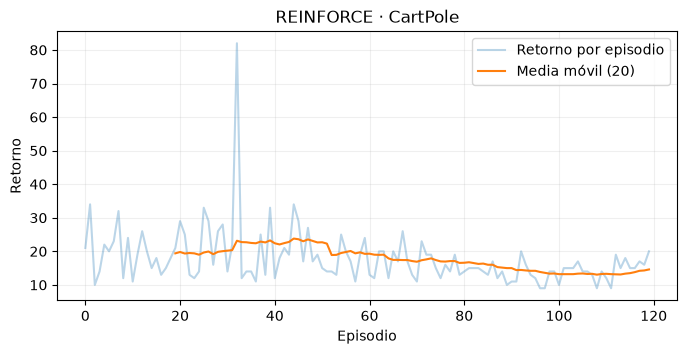

In [16]:
if reinforce_returns:
    plt.figure(figsize=(8,3.5))
    plt.plot(reinforce_returns, alpha=0.3, label='Retorno por episodio')
    ma = moving_average(reinforce_returns,20)
    plt.plot(np.arange(len(ma))+19,ma,label='Media móvil (20)')
    plt.xlabel('Episodio');plt.ylabel('Retorno');plt.title('REINFORCE · CartPole')
    plt.legend();plt.grid(alpha=.2);plt.show()

## <span style="color:#bd232b">5. Evaluación independiente: aprendizaje no equivale a rendimiento</span>

Una política estocástica debe evaluarse sin actualizar sus pesos y con semillas diferentes de las utilizadas durante el entrenamiento. Presentamos media, desviación estándar y retornos individuales. Las diferencias entre corridas pueden ser importantes: un resultado aislado no demuestra superioridad.

In [17]:
def evaluate_policy(policy, n_episodes=10, seed=9000, deterministic=True):
    if not GYM_OK:
        return np.array([])
    env = gym.make('CartPole-v1')
    scores=[]
    for i in range(n_episodes):
        state,_ = env.reset(seed=seed+i)
        score=0.0
        while True:
            with torch.no_grad():
                #dist=policy(torch.as_tensor(state,dtype=torch.float32))
                resultado = policy(torch.as_tensor(state, dtype=torch.float32))
                dist = resultado[0] if isinstance(resultado, tuple) else resultado
               
                action = torch.argmax(dist.logits).item() if deterministic else dist.sample().item()
            state,reward,terminated,truncated,_ = env.step(int(action))
            score += reward
            if terminated or truncated:break
        scores.append(score)
    env.close()
    return np.asarray(scores)

if GYM_OK and reinforce_returns:
    pg_eval=evaluate_policy(reinforce_policy)
    print(f'REINFORCE: media={pg_eval.mean():.1f}, DE={pg_eval.std(ddof=1):.1f}; episodios={pg_eval.tolist()}')

REINFORCE: media=13.5, DE=1.6; episodios=[14.0, 13.0, 13.0, 15.0, 12.0, 16.0, 15.0, 11.0, 14.0, 12.0]


## <span style="color:#bd232b">6. Por qué aparece un baseline</span>

El estimador $\nabla_\theta\log\pi_\theta(a_t\mid s_t)G_t$ puede tener gran varianza. Podemos sustraer una función $b(s_t)$ que **no dependa de la acción** sin alterar la esperanza del gradiente:

$$
\mathbb E_{a\sim\pi_\theta(\cdot\mid s)}[\nabla_\theta\log\pi_\theta(a\mid s)b(s)]
=b(s)\nabla_\theta\sum_a\pi_\theta(a\mid s)=0.
$$

Si usamos $b(s)=V^\pi(s)$, el término $G_t-V^\pi(s_t)$ estima la **ventaja** de la acción respecto al rendimiento habitual en ese estado:

$$A^\pi(s,a)=Q^\pi(s,a)-V^\pi(s).$$

En REINFORCE con baseline, un crítico $V_\phi(s)$ aprende a predecir retornos completos. El actor usa la ventaja estimada y el crítico minimiza error cuadrático. En Actor-Crítico de un paso, se utiliza una estimación temporal más inmediata.

## <span style="color:#bd232b">7. Actor-Crítico: derivación de la ventaja temporal</span>

Con un crítico $V_\phi(s)$, la **diferencia temporal** es

$$\delta_t=r_{t+1}+\gamma(1-d_t)V_\phi(s_{t+1})-V_\phi(s_t),$$

donde $d_t=1$ cuando el episodio termina realmente (*terminated*), no necesariamente cuando se corta por límite de tiempo (*truncated*).

En el actor usamos $\delta_t$ como estimador aproximado de la ventaja:

$$\mathcal L_{\mathrm{actor}}=-\log\pi_\theta(a_t\mid s_t)\,\operatorname{stopgrad}(\delta_t),$$

$$\mathcal L_{\mathrm{crítico}}=\frac12\left[V_\phi(s_t)-\operatorname{stopgrad}(r_{t+1}+\gamma(1-d_t)V_\phi(s_{t+1}))\right]^2.$$

El operador $\operatorname{stopgrad}$ significa que el objetivo se trata como constante al calcular gradientes. La regularización entrópica $-\beta\mathcal H(\pi_\theta)$ puede promover exploración.

**Dos distinciones importantes:** (1) *Actor-Crítico* es una familia, no un algoritmo único; (2) esta implementación usa actualizaciones en línea de un paso y no es una implementación de A2C paralela ni de PPO.

<img src="../Imagenes/Flujo-de-aprendizaje-actor-crítico.png" width="860"/>

*Figura propuesta 103-1 (nueva, pendiente de generación): interacción entre entorno, actor, crítico, error TD y actualizaciones. Su referencia queda preparada para el repositorio.*

## <span style="color:#bd232b">8. Implementación de Actor-Crítico en CartPole</span>

In [18]:
class ActorCritic(nn.Module):
    def __init__(self, obs_dim=4, act_dim=2, hidden=64):
        super().__init__()
        self.body=nn.Sequential(nn.Linear(obs_dim,hidden),nn.Tanh(),
                                nn.Linear(hidden,hidden),nn.Tanh())
        self.actor=nn.Linear(hidden,act_dim)
        self.critic=nn.Linear(hidden,1)
    def forward(self, states):
        z=self.body(states)
        return Categorical(logits=self.actor(z)), self.critic(z).squeeze(-1)

def actor_critic_episode(env, model, optimizer, gamma=.99, beta=.005, seed=None):
    state,_=env.reset(seed=seed)
    score=0.0
    while True:
        x=torch.as_tensor(state,dtype=torch.float32)
        dist,value=model(x)
        action=dist.sample()
        next_state,reward,terminated,truncated,_=env.step(int(action.item()))
        with torch.no_grad():
            _, next_value=model(torch.as_tensor(next_state,dtype=torch.float32))
            target=torch.tensor(float(reward)) + gamma*(1.0-float(terminated))*next_value
        delta=target-value
        loss_actor= -dist.log_prob(action)*delta.detach()-beta*dist.entropy()
        loss_critic=0.5*delta.square()
        loss=loss_actor+loss_critic
        optimizer.zero_grad();loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
        optimizer.step()
        score+=float(reward)
        state=next_state
        if terminated or truncated:break
    return score

# Comprobación de formas y de existencia de gradientes.
ac_probe=ActorCritic()
d,v=ac_probe(torch.zeros(4))
assert d.probs.shape==(2,) and v.ndim==0
assert abs(d.probs.sum().item()-1)<1e-6
(-d.log_prob(torch.tensor(0))+v.square()).backward()
assert any(p.grad is not None for p in ac_probe.parameters())
print('Prueba de Actor-Crítico: correcta.')

Prueba de Actor-Crítico: correcta.


In [19]:
AC_EPISODES=120
ac_model=ActorCritic().to(DEVICE)
ac_returns=[]
if GYM_OK:
    env=gym.make('CartPole-v1')
    opt_ac=torch.optim.Adam(ac_model.parameters(),lr=5e-4)
    for ep in range(AC_EPISODES):
        ac_returns.append(actor_critic_episode(env,ac_model,opt_ac,seed=SEED+ep))
    env.close()
    print('Actor-Crítico, últimos 20:',round(np.mean(ac_returns[-20:]),1))
else:
    print('Se omite entrenamiento hasta instalar Gymnasium.')

Actor-Crítico, últimos 20: 9.0


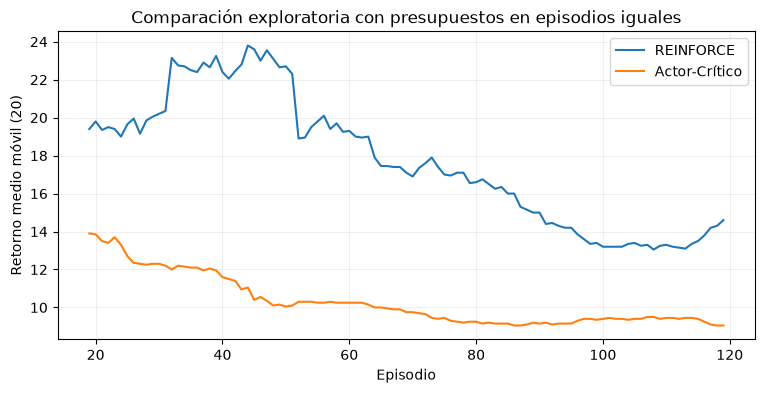

Evaluación Actor-Crítico: [9.0, 10.0, 9.0, 9.0, 10.0, 8.0, 9.0, 11.0, 9.0, 10.0]


In [20]:
if reinforce_returns and ac_returns:
    plt.figure(figsize=(9,4))
    for scores,label in [(reinforce_returns,'REINFORCE'),(ac_returns,'Actor-Crítico')]:
        ma=moving_average(scores,20)
        plt.plot(np.arange(len(ma))+19,ma,label=label)
    plt.xlabel('Episodio');plt.ylabel('Retorno medio móvil (20)')
    plt.title('Comparación exploratoria con presupuestos en episodios iguales')
    plt.legend();plt.grid(alpha=.2);plt.show()
    print('Evaluación Actor-Crítico:',evaluate_policy(ac_model).tolist())

**Advertencia metodológica:** igual número de episodios no implica igual número de pasos de interacción. REINFORCE y Actor-Crítico tampoco tienen necesariamente el mismo costo computacional. Esta gráfica es **ilustrativa**, no una prueba de superioridad. Una comparación formal exigiría igual presupuesto de pasos, varias semillas de entrenamiento, evaluación pareada y bandas de incertidumbre.

## <span style="color:#bd232b">9. Del control discreto al continuo: preparación para Hydro-Lab</span>

CartPole tiene una distribución categórica sobre dos acciones. Hydro-Lab tiene **15 componentes de observación** y **3 controles continuos normalizados** en $[-1,1]^3$ (uno por bomba). Para este caso, un actor puede parametrizar una distribución gaussiana, por ejemplo

$$u_t\sim\mathcal N(\mu_\theta(o_t),\operatorname{diag}(\sigma_\theta^2(o_t))),\qquad a_t=\tanh(u_t).$$

La transformación $\tanh$ mantiene las acciones en $(-1,1)^3$; al calcular la densidad de la acción transformada es necesario considerar el jacobiano de cambio de variables. Otra opción es utilizar una distribución gaussiana y recortar la acción en el entorno, como ocurre en algunas implementaciones prácticas, teniendo presente la distinción entre acción muestreada y ejecutada.

El crítico estima $V_\phi(o_t)$ o $V_\phi(s_t)$ según la información disponible. En Hydro-Lab **la política no debe recibir** información privilegiada reservada a la evaluación (`info['evaluation_truth']`).

La observación no debe confundirse con el estado físico completo. El agente aprende a partir de las variables efectivamente observables.

<img src="../Imagenes/arquitectura_laboratorio_G2.4.png" width="950"/>

*Figura del proyecto Hydro-Lab G2.4: contexto físico y computacional de la red de hidrocarburos. No es una figura nueva de este cuaderno.*

## <span style="color:#bd232b">10. Puente conceptual hacia PPO (cuaderno 104)</span>

El Actor-Crítico básico permite grandes cambios en los parámetros después de cada actualización. PPO introduce una política de referencia $\pi_{\theta_{\mathrm{old}}}$ y limita el incentivo a cambiar demasiado la razón de probabilidades

$$r_t(\theta)=\frac{\pi_\theta(a_t\mid o_t)}{\pi_{\theta_{\mathrm{old}}}(a_t\mid o_t)}.$$

El objetivo recortado es

$$L^{\mathrm{CLIP}}(\theta)=\mathbb E_t\left[\min\left(r_t(\theta)\hat A_t,\operatorname{clip}(r_t(\theta),1-\epsilon,1+\epsilon)\hat A_t\right)\right].$$

PPO combina típicamente (i) actor, (ii) crítico, (iii) ventajas estimadas —frecuentemente GAE—, (iv) múltiples épocas sobre un lote y (v) un objetivo recortado. **El clipping no garantiza por sí solo restricciones hidráulicas ni seguridad operacional.**

En Hydro-Lab se entrenan y evalúan políticas PPO con separación de semillas y comparación frente a controladores de referencia. La evidencia disponible no permite afirmar que PPO supere siempre las líneas base.

## <span style="color:#bd232b">11. Actividad de contraste y ejercicios</span>

**Actividad de clase (5 minutos).** Explica, sin ejecutar el entrenamiento, qué debe aprender cada componente para operar las tres bombas de Hydro-Lab. Identifica qué variables de la observación alimentan al actor y cuáles al crítico, qué consecuencias puede tener una recompensa mal diseñada y por qué un aumento del retorno no basta para certificar operación segura.

**E1 — Derivación.** Demuestra que el baseline independiente de la acción tiene esperanza de gradiente cero.

**E2 — Signo.** Si una acción tuvo ventaja negativa, ¿cómo debe cambiar su log-probabilidad bajo descenso de gradiente de la pérdida del actor?

**E3 — Sesgo/varianza.** Compara el retorno Monte Carlo completo con el objetivo TD de un paso: ¿qué cambia al sustituir datos reales futuros por predicciones del crítico?

**E4 — Experimento.** Ejecuta REINFORCE y Actor-Crítico con cinco semillas distintas y un presupuesto igual de pasos de entorno. Informa media, desviación y distribución de retornos de evaluación.

**E5 — Horizonte.** Explica por qué `truncated=True` y `terminated=True` no son equivalentes para el valor bootstrap.

**E6 — Hydro-Lab.** Diseña un actor de tres salidas continuas y un crítico escalar; especifica dimensiones, activaciones, rango de acciones y fuentes de observación permitidas.

## <span style="color:#bd232b">12. Comprobaciones de consistencia y reproducibilidad</span>

In [21]:
# Pruebas sin entrenamiento largo.
assert discounted_returns([1, 0, 2], gamma=1).tolist()==[3.0,2.0,2.0]
assert len(list(PolicyNetwork().parameters()))>0
for net in [PolicyNetwork(),ActorCritic()]:
    assert all(torch.isfinite(p).all() for p in net.parameters())
assert set(['terminated','truncated']) <= set(['terminated','truncated'])
print('Comprobaciones numéricas y estructurales: correctas.')

Comprobaciones numéricas y estructurales: correctas.


## <span style="color:#bd232b">13. Fuentes, figuras, licencia y continuidad editorial</span>

### 13.1 Cuadernos originales utilizados

- `12_ar_Gradientes_Politica.ipynb`: derivación de gradientes de política, REINFORCE, línea base y ejemplo CartPole. **Fuente principal de la primera mitad**.
- `13_ar_Actor_Critico.ipynb`: crítico, ventaja temporal, arquitectura Actor-Crítico y transición a A2C. **Fuente principal de la segunda mitad**.
- `07_ar_Metodo_Entropia_Cruzada_Introducción.ipynb` y `08_ar_Metodo_Entropia_Cruzada_implementacion.ipynb`: antecedentes sobre aprendizaje directo de políticas y entrenamiento por episodios; **no se reproducen sus algoritmos** en esta sesión por límite de tiempo.
- `102_ar_Q_Learning_DQN.ipynb`: prerrequisito sobre aprendizaje de valores y CartPole.
- `Manual_Hydro_Lab_S2.11_G3.1.md`: contexto del simulador y del control industrial.

**Adaptación:** las interfaces antiguas de Gym y ejemplos extensos en Pong se sustituyen por implementaciones docentes autocontenidas en PyTorch/Gymnasium y un puente explícito hacia Hydro-Lab. No se modifican los originales.

### 13.2 Bibliografía

- Sutton, R. S. y Barto, A. G. (2018). *Reinforcement Learning: An Introduction*, 2.ª ed., MIT Press, capítulo 13.
- Williams, R. J. (1992). *Simple statistical gradient-following algorithms for connectionist reinforcement learning*. Machine Learning, 8, 229–256.
- Konda, V. R. y Tsitsiklis, J. N. (2000). *Actor-Critic Algorithms*. NeurIPS.
- Mnih, V. et al. (2016). *Asynchronous Methods for Deep Reinforcement Learning*. ICML.
- Schulman, J. et al. (2017). *Proximal Policy Optimization Algorithms*. arXiv:1707.06347.
- Farama Foundation. *Gymnasium Documentation*.

### 13.3 Figuras y rutas

- `../Imagenes/logo-final-ap.png` — logotipo institucional, existente.
- `../Imagenes/Ejemplo_polea.gif` — CartPole, existente.
- `../Imagenes/arquitectura_laboratorio_G2.4.png` — arquitectura Hydro-Lab, existente en el proyecto.
- `../Imagenes/actor_critico_flujo_103.png` — **nueva, pendiente de generación**; figura de flujo Actor-Crítico. La ruta queda referenciada, pero la imagen no se incluye aún.

### 13.4 Licencia

**MIT License**, para las contribuciones originales de esta nueva edición (texto y código). Copyright (c) 2026 Alvaro Montenegro, Daniel Montenegro y Pilar Montenegro. La licencia MIT permite reutilización, modificación y distribución bajo sus condiciones. **Las imágenes, extractos y demás recursos de terceros conservan sus licencias y atribuciones propias; esta declaración no cambia sus derechos.** El archivo `LICENSE` de la colección contiene el texto legal.